# Basic Distributions

`braintools.init` describes *how to create* a parameter array, separately from the array itself. An initializer is a small object; calling it with a shape returns the values:

```python
w = init.Normal(0.5 * u.nS, 0.1 * u.nS)((100, 50))   # a (100, 50) Quantity in nS
```

This tutorial covers the basic distributions:

| Initializer | Parameters | Values |
|---|---|---|
| `Constant(value)` | the value | every element equals `value` |
| `ZeroInit(unit=...)` | optional unit | zeros |
| `Uniform(low, high)` | bounds | uniform on `[low, high)` |
| `Normal(mean, std)` | mean, standard deviation | Gaussian |
| `TruncatedNormal(mean, std, low=None, high=None)` | parent Gaussian and bounds | Gaussian restricted to `[low, high]` |
| `LogNormal(mean, std)` | mean and std **of the samples** | positive, right-skewed |
| `Gamma(shape, scale)` | shape $k$, scale $\theta$ | positive, mean $k\theta$ |
| `Exponential(scale)` | scale $\lambda$ | positive, mean $\lambda$ |
| `Weibull(shape, scale)` | shape $k$, scale $\lambda$ | positive |
| `Beta(alpha, beta, low, high)` | shape parameters and range | bounded on `[low, high]` |

Variance-scaling and orthogonal initializers for deep networks are covered in the next tutorial.

## 1. Setup

In [1]:
import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st

from braintools import init

## 2. Calling an Initializer

An initializer is called with a shape (an `int` or a tuple) and returns a NumPy/JAX array, or a `brainunit.Quantity` when its parameters carry units. Random initializers accept an optional `rng=` keyword:

- with `rng=np.random.default_rng(seed)` (or any object with the same sampling methods) the draw comes from that generator;
- without it they draw from `brainstate.random`, which you seed with `brainstate.random.seed(...)`.

Seeding NumPy's global state (`np.random.seed`) has **no** effect on `braintools.init`.

In [2]:
normal = init.Normal(mean=0.5 * u.nS, std=0.1 * u.nS)

w = normal((3, 4), rng=np.random.default_rng(0))
print(f"shape {w.shape}, unit {w.unit}")

# Same generator seed -> same values
print("same rng seed reproduces:", bool(u.math.all(w == normal((3, 4), rng=np.random.default_rng(0)))))

# Default backend: brainstate.random
brainstate.random.seed(42)
a = normal(5)
brainstate.random.seed(42)
b = normal(5)
print("brainstate seed reproduces:", bool(u.math.all(a == b)))

shape (3, 4), unit nS


same rng seed reproduces: True


brainstate seed reproduces: True


Parameters may use any compatible units; they are converted to the unit of the first parameter. Incompatible units raise an error instead of producing silently wrong numbers.

In [3]:
rng = np.random.default_rng(0)
v_init = init.Normal(-65.0 * u.mV, 0.002 * u.volt)  # std given in volts
print(v_init(4, rng=rng))

try:
    init.Normal(-65.0 * u.mV, 2.0 * u.nS)(4, rng=rng)
except u.UnitMismatchError as exc:
    print("incompatible units ->", type(exc).__name__)

[-64.74853956 -65.26420973 -63.7191547  -64.79019977] mV
incompatible units -> UnitMismatchError


## 3. Deterministic Values: `Constant` and `ZeroInit`

Use these for biases, resting potentials, and other initial *states*. They are a poor choice for weights: if every weight in a layer is equal, every unit receives the same input and the same gradient, so the units stay identical during training. Random initialization is what breaks this symmetry.

In [4]:
print(init.Constant(-65.0 * u.mV)((2, 3)))
print(init.ZeroInit()(3))
print(init.ZeroInit(unit=u.mV)(3))

[[-65. -65. -65.]
 [-65. -65. -65.]] mV
[0. 0. 0.]
[0. 0. 0.] mV


## 4. Checking Every Distribution Against Its Theory

Each random initializer draws from a standard distribution. Below, 200,000 samples per initializer are compared with the exact mean and standard deviation from `scipy.stats`. Two parameterizations deserve attention:

- `LogNormal(mean, std)` takes the mean and standard deviation of the **samples themselves** (linear space), not of $\log x$. Internally it uses $\sigma_{\log}^2 = \ln(1 + s^2/m^2)$ and $\mu_{\log} = \ln m - \sigma_{\log}^2/2$.
- `TruncatedNormal(mean, std, low, high)` takes the parameters of the **parent** Gaussian. After truncation the sample mean and standard deviation differ from `mean` and `std` (the standard deviation is always smaller).

In [5]:
def lognormal_ref(m, s):
    sigma2 = np.log(1 + s ** 2 / m ** 2)
    return st.lognorm(s=np.sqrt(sigma2), scale=np.exp(np.log(m) - sigma2 / 2))


cases = {
    "Uniform(0.1, 1.0)": (init.Uniform(0.1 * u.nS, 1.0 * u.nS), st.uniform(0.1, 0.9)),
    "Normal(0.5, 0.15)": (init.Normal(0.5 * u.nS, 0.15 * u.nS), st.norm(0.5, 0.15)),
    "TruncatedNormal(0.5, 0.2, 0.3, 0.9)": (
        init.TruncatedNormal(0.5 * u.nS, 0.2 * u.nS, low=0.3 * u.nS, high=0.9 * u.nS),
        st.truncnorm((0.3 - 0.5) / 0.2, (0.9 - 0.5) / 0.2, loc=0.5, scale=0.2),
    ),
    "LogNormal(0.5, 0.2)": (init.LogNormal(0.5 * u.nS, 0.2 * u.nS), lognormal_ref(0.5, 0.2)),
    "Gamma(2, 0.25)": (init.Gamma(shape=2.0, scale=0.25 * u.nS), st.gamma(2.0, scale=0.25)),
    "Exponential(0.3)": (init.Exponential(scale=0.3 * u.nS), st.expon(scale=0.3)),
    "Weibull(2, 0.5)": (init.Weibull(shape=2.0, scale=0.5 * u.nS), st.weibull_min(2.0, scale=0.5)),
    "Beta(2, 5, 0, 1)": (init.Beta(2.0, 5.0, low=0.0 * u.nS, high=1.0 * u.nS), st.beta(2.0, 5.0)),
}

rng = np.random.default_rng(0)
samples = {}
print(f"{'initializer (nS)':38s} {'mean':>7s} {'theory':>7s} {'std':>7s} {'theory':>7s}")
for name, (initializer, ref) in cases.items():
    x = initializer(200_000, rng=rng).to_decimal(u.nS)
    samples[name] = (x, ref)
    print(f"{name:38s} {x.mean():7.4f} {ref.mean():7.4f} {x.std():7.4f} {ref.std():7.4f}")

initializer (nS)                          mean  theory     std  theory
Uniform(0.1, 1.0)                       0.5494  0.5500  0.2594  0.2598
Normal(0.5, 0.15)                       0.5000  0.5000  0.1502  0.1500


TruncatedNormal(0.5, 0.2, 0.3, 0.9)     0.5462  0.5459  0.1443  0.1442
LogNormal(0.5, 0.2)                     0.5002  0.5000  0.1997  0.2000
Gamma(2, 0.25)                          0.5005  0.5000  0.3544  0.3536
Exponential(0.3)                        0.2999  0.3000  0.2999  0.3000
Weibull(2, 0.5)                         0.4429  0.4431  0.2311  0.2316
Beta(2, 5, 0, 1)                        0.2855  0.2857  0.1596  0.1597


The histograms below overlay the exact density on each sample. The positive-valued families differ mainly in their tails: the log-normal has the heaviest right tail, the Weibull with shape 2 the lightest.

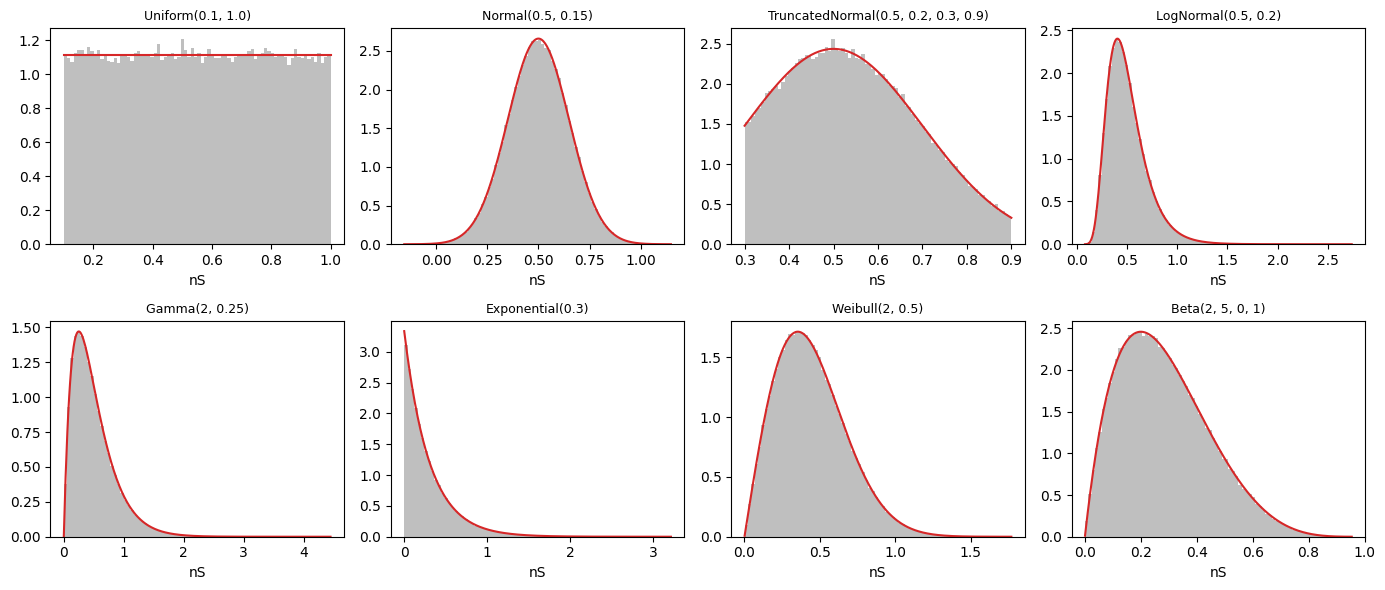

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharey=False)
for ax, (name, (x, ref)) in zip(axes.flat, samples.items()):
    ax.hist(x, bins=80, density=True, color="0.75")
    grid = np.linspace(x.min(), x.max(), 300)
    ax.plot(grid, ref.pdf(grid), color="C3", lw=1.5)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("nS")
fig.tight_layout()
plt.show()

## 5. Truncation versus Clipping

Both `TruncatedNormal` and clipping keep values inside bounds, but they produce different distributions. Truncation **redraws** out-of-range values, so the density stays smooth. Clipping (`.clip(...)`, covered in the composition tutorial) **moves** out-of-range values onto the bound, which piles up probability mass exactly at the boundary.

truncated: range [0.200, 0.800], fraction exactly on a bound = 0.000
clipped  : range [0.200, 0.800], fraction exactly on a bound = 0.317


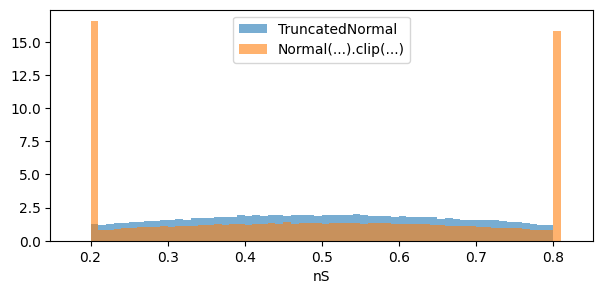

In [7]:
rng = np.random.default_rng(1)
truncated = init.TruncatedNormal(0.5 * u.nS, 0.3 * u.nS, low=0.2 * u.nS, high=0.8 * u.nS)(100_000, rng=rng).to_decimal(u.nS)
clipped = init.Normal(0.5 * u.nS, 0.3 * u.nS).clip(0.2 * u.nS, 0.8 * u.nS)(100_000, rng=rng).to_decimal(u.nS)

for name, x in [("truncated", truncated), ("clipped", clipped)]:
    at_bounds = np.mean((x == 0.2) | (x == 0.8))
    print(f"{name:9s}: range [{x.min():.3f}, {x.max():.3f}], fraction exactly on a bound = {at_bounds:.3f}")

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0.18, 0.82, 65)
ax.hist(truncated, bins=bins, density=True, alpha=0.6, label="TruncatedNormal")
ax.hist(clipped, bins=bins, density=True, alpha=0.6, label="Normal(...).clip(...)")
ax.set_xlabel("nS")
ax.legend()
plt.show()

## 6. Example: Heterogeneous Neuron and Synapse Parameters

Parameters of biological models are rarely identical across a population. The distributions above give heterogeneity with the right support:

- strictly positive quantities (conductances, time constants, rates) come from `LogNormal`, `Gamma`, or a `TruncatedNormal` with `low=0`;
- quantities with hard physiological bounds use `TruncatedNormal` or `Beta`;
- quantities that may take either sign use `Normal`.

The parameter values below are illustrative, not fitted to data.

In [8]:
rng = np.random.default_rng(2)
n = 1000

params = {
    "membrane tau": init.LogNormal(20.0 * u.ms, 5.0 * u.ms)(n, rng=rng),
    "resting potential": init.Normal(-65.0 * u.mV, 2.0 * u.mV)(n, rng=rng),
    "threshold": init.TruncatedNormal(-50.0 * u.mV, 2.0 * u.mV, low=-55.0 * u.mV, high=-45.0 * u.mV)(n, rng=rng),
    "baseline rate": init.Gamma(shape=2.0, scale=2.5 * u.Hz)(n, rng=rng),
    "release probability": init.Beta(2.0, 3.0, low=0.0, high=1.0)(n, rng=rng),
}
for name, value in params.items():
    print(f"{name:20s} mean {u.math.mean(value):.3f}  min {u.math.min(value):.3f}  max {u.math.max(value):.3f}")

membrane tau         mean 19.912 ms  min 9.307 ms  max 41.729 ms
resting potential    mean -65.181 mV  min -71.166 mV  max -58.844 mV
threshold            mean -49.929 mV  min -54.915 mV  max -45.044 mV
baseline rate        mean 5.176 Hz  min 0.239 Hz  max 27.308 Hz
release probability  mean 0.409  min 0.008  max 0.978


## 7. Choosing a Distribution

| Need | Candidates |
|---|---|
| A fixed value (bias, resting state) | `Constant`, `ZeroInit` |
| Symmetric noise around a mean | `Normal`, `Uniform` |
| Gaussian-like but within hard bounds | `TruncatedNormal` |
| Strictly positive, right-skewed | `LogNormal` (heavy tail), `Gamma`, `Weibull`, `Exponential` |
| A fraction or probability | `Beta` with `low=0, high=1` |
| Weights of a deep network | variance scaling (next tutorial) |

## Summary

- Initializers are objects called with a shape; units on the parameters carry through to the result.
- Pass `rng=np.random.default_rng(seed)` for reproducible draws, or seed `brainstate.random`; `np.random.seed` does not affect them.
- `LogNormal` takes the mean and standard deviation of the samples; `TruncatedNormal` takes those of the parent Gaussian.
- Truncation redraws, clipping piles mass on the bounds.